# M14.7 — Re-selección de la configuración del Mondrian para el modelo final

Pre-registro: `docs/experiments/M14_7_mondrian_reselection.md` (12-11-2026). Modelo: `MODEL_TAG` (por defecto M14.5a; si el 13-11 se elige M14.5b, se cambia solo `MODEL_TAG` y se repite sin más cambios).

- **Espacio de búsqueda (por etiqueta):** el de la selección de M11 (`M11_12` celda 2: taxonomías `prediction`/`difficulty`, n.º de bins {4, 6, 8, 12, 16, 24, 32, 48}, simétrico/asimétrico, kNN de dificultad con k = 5, el único valor de M11), más 1 bin (sin taxonomía) y score r o r/σ (σ = √diag Σ de M14.5; r/σ con los bins de r, como `fit_v2` de M14.3). Una sola política.
- **Datos:** todo se ajusta en cal (bins, cuantiles, referencias kNN); val solo evalúa y selecciona; test se usa una vez, en la sección 8, para la configuración elegida (y la alternativa heredada del doc).
- **Validez (val):** (1) cobertura marginal no por debajo del límite inferior de la banda Monte Carlo al 95 % con ruido de cal (sentencias de la celda 13 de M13.13, reutilizadas por AST como en la enmienda 2 de M14.5); (2) ningún bin por debajo del límite inferior de su banda Beta-Binomial al 99 % (mismo cálculo que M13.13 celda 13); (3) máx. |cobertura − 0,90| ≤ 0,015 en terciles de τ30 predicha (cortes en cal) y de SNR nominal (cortes de val de M14.3). `default_rng(147001)`, un generador en orden fijo.
- **Eficiencia:** menor anchura media (física) en val entre las válidas; si varias están dentro del 1 % de la mejor, menos bins y simétrica antes que asimétrica.
- **Test:** la elegida debe cumplir 1–3 con el n de test (`default_rng(147002)`); si falla, se usa la heredada de M11 (conservative) con score r/σ.
- **Salidas:** `results/M13_3/M14_7/<MODEL_TAG>/run_<UTC>/` (bundle de calibradores ajustados en cal, JSON de selección escrito antes de test, resumen JSON y figuras). JSON en modo `'x'`.

## 1. Parámetros y CONFIG

In [1]:
# ---- Variant: edit only MODEL_TAG ----
MODEL_TAG = "M14_5a_4a_G3T_fullcov_s123"          # or "M14_5b_4a_G3T_tbank_fullcov_s123" (decision of 13-11)

VARIANTS = {
    "M14_5a_4a_G3T_fullcov_s123": dict(
        train_cfg="configs/experiments/m14/train_m14_5a_4aG3T_fullcov_s123.json", template_bank=False),
    "M14_5b_4a_G3T_tbank_fullcov_s123": dict(
        train_cfg="configs/experiments/m14/train_m14_5b_4aG3T_tbank_fullcov_s123.json", template_bank=True),
}
VARIANT = VARIANTS[MODEL_TAG]
TRAIN_CFG_REL = VARIANT["train_cfg"]
EXPECTED_CHECKPOINT_NAME = f"{MODEL_TAG}_final.pt"
G3T_MARK = "m13_13_g3t"
# Test inference reads fp16_memmap_heldout, the cal memmap directory (as in M14.5 cell 30).
MEMMAP_NAMES = {"cal": "fp16_memmap_heldout", "val": "fp16_memmap", "test": "fp16_memmap_heldout"}

# Inputs (relative to <data_root>/results/). Test: only in section 8.
PRED_REL = {s: f"M13_3/{MODEL_TAG}/preds_{s}_G3T/{s}_predictions_embeddings.npz" for s in ("cal", "val", "test")}
G3_CFG_REL = "configs/experiments/m13/train_m13_4a_G3aug_s123.json"   # G3 HDF5: y and SNR, as in M14.1-M14.5
SNR_KEY = "target_network_snr"
M14_3_SUMMARY_NAME = "M14_3_summary_20261111T153122Z.json"           # val SNR tercile cuts
INHERITED_POLICY = "conservative"                                     # M11 selection used by M13.7, M14.3, M14.5

# Gates (same tolerances as M14.5).
N_EXPECTED = {"cal": 30_000, "val": 40_000, "test": 30_000}
Y_RTOL, Y_ATOL = 1e-5, 1e-6
SYM_ATOL = 1e-6
SIGMA_ATOL = 1e-6
REPRO_ATOL = 1e-12

# Search space: M11 grid (M11_12 cell 2; gated below against the M11 provenance JSON) + 1 bin + score.
N_BINS_GRID = [4, 6, 8, 12, 16, 24, 32, 48]
TAXONOMY_MODES = ["prediction", "difficulty"]
INTERVAL_MODES = ["symmetric", "asymmetric"]
N_NEIGHBORS_GRID = [5]                 # the only k of the M11 selection
ONE_BIN = True                         # added option: 1 bin, no taxonomy
SCORES = ["r", "r/sigma"]              # r = y - mu; r/sigma with sigma = sqrt(diag Sigma) (M14.3 / M14.5)
HP_EXPECTED = dict(confidence_level=.9, n_neighbors=5, min_samples_per_bin=20, apply_jitter=True,
                   jitter_variation=1e-10)

# Pre-registered validity and efficiency.
LEVEL = 0.90
MARGINAL_BAND_LEVEL = 0.95             # (1) Monte Carlo band with cal noise; validity = not below its lower limit
BIN_BAND_LEVEL = 0.99                  # (2) central Beta-Binomial band per bin; no bin below its lower limit
MC_REPLICAS = 100_000                  # as M13.13 and M14.5 amendment 2
COND_MAX_GAP = 0.015                   # (3) max |coverage - 0.90| over terciles of predicted tau30 and of SNR
N_TERCILES = 3
WIDTH_TIE_FRACTION = 0.01              # efficiency: within 1 % of the best mean width
SEED_VAL, SEED_TEST = 147001, 147002

CONFIG = dict(
    labels={"chirp_mass": "chirp mass", "total_mass": "total mass", "chi_eff": "χ_eff"},
    units={"chirp_mass": "M☉", "total_mass": "M☉", "chi_eff": "adim."},
    taxonomy=dict(prediction=dict(name="prediction", color="#2a6fb0"),
                  difficulty=dict(name="difficulty (kNN)", color="#c4512b"),
                  none=dict(name="1 bin", color="0.25")),
    score={"r": dict(name="r", ls="-"), "r/sigma": dict(name="r/σ", ls="--")},
    interval=dict(symmetric=dict(name="simétrico", marker="o"), asymmetric=dict(name="asimétrico", marker="s")),
    selected=dict(name="elegida (M14.7)", color="#2a6fb0", marker="o"),
    inherited_r=dict(name="heredada M11, r", color="0.55", marker="s"),
    inherited_rs=dict(name="heredada M11, r/σ", color="#c4512b", marker="^"),
    band_color="0.85",
    fig_names=dict(width=f"{MODEL_TAG}_M14_7_val_mean_width_vs_n_bins",
                   snr=f"{MODEL_TAG}_M14_7_coverage_by_snr_tercile_selected_vs_m11"),
)

## 2. Imports, rutas y código reutilizado

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta, betabinom
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.conformal.pipeline import (fit_mondrian, apply_mondrian, evaluate_mondrian, MondrianPrediction,
                                    FittedMondrianRegressor)
from src.conformal.selected_calibrators import SelectedMondrianCalibrator
from src.conformal.binning import BinGrouper                       # used by the reused fit_v2 and the 1-bin fit
from src.conformal.calibration import ConformalIntervalCalibrator  # used by the reused fit_v2 and the 1-bin fit
from scripts.m13.m13_1_diagnostics import tau_newtonian            # same tau30 as M14.1-M14.5

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]

train_cfg = read_json(PROJECT_ROOT / TRAIN_CFG_REL)
require(train_cfg["outputs"]["checkpoint_tag"] == MODEL_TAG, "train config checkpoint_tag != MODEL_TAG")
require(train_cfg["model"].get("heteroscedastic") is True and train_cfg["model"].get("covariance") == "full",
        "train config is not a full-covariance heteroscedastic model")
require(bool(train_cfg["model"].get("template_bank")) == VARIANT["template_bank"], "template bank flag of the variant")
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID_G3T = train_cfg["dataset"]["dataset_id"]
require(DATASET_ID_G3T == f"M13_G3_band1024_w16_500k/{G3T_MARK}", "Unexpected dataset")
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
g3_ds = read_json(PROJECT_ROOT / G3_CFG_REL)["dataset"]
DATASET_ID_G3 = g3_ds["dataset_id"]
require(G3T_MARK not in DATASET_ID_G3 and DATASET_ID_G3T == f"{DATASET_ID_G3}/{G3T_MARK}", "G3 / G3T dataset ids")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3, file_name=g3_ds["dataset_file"])
G3T_DIR = DATA_ROOT / "processed" / DATASET_ID_G3T
MEMMAP_DIRS = {s: G3T_DIR / name for s, name in MEMMAP_NAMES.items()}

RESULTS = DATA_ROOT / "results"
M13_DIR = RESULTS / "M13_3"
PRED_PATHS = {s: RESULTS / rel for s, rel in PRED_REL.items()}
M14_3_SUMMARY = M13_DIR / "M14_3" / M14_3_SUMMARY_NAME
M11_RESULTS = RESULTS / "M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"
M11_GRID_PROVENANCE = M11_RESULTS / "mondrian_m11_cal_val_test_provenance.json"
NOTEBOOK_PATHS = {"M13_7": PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb",
                  "M13_13": PROJECT_ROOT / "notebooks/m13/M13_13_mondrian_G3T.ipynb",
                  "M14_3": PROJECT_ROOT / "notebooks/m14/M14_3_mondrian_v2.ipynb",
                  "M14_4": PROJECT_ROOT / "notebooks/m14/M14_4_residual_correlation.ipynb",
                  "M14_5": PROJECT_ROOT / "notebooks/m14/M14_5_evaluation.ipynb"}

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT_ROOT = M13_DIR / "M14_7" / MODEL_TAG
RUN_DIR = OUT_ROOT / f"run_{RUN_STAMP}"
FIG_DIR = RUN_DIR / "figures"
BUNDLE_PATH = RUN_DIR / f"M14_7_mondrian_calibrators_cal_only_{RUN_STAMP}.pkl"
SELECTION_JSON = RUN_DIR / f"M14_7_selection_val_{RUN_STAMP}.json"
SUMMARY_JSON = RUN_DIR / f"M14_7_summary_{RUN_STAMP}.json"
require(not RUN_DIR.exists(), "Output of this stamp already exists")

inputs_to_check = [("pred cal", PRED_PATHS["cal"]), ("pred val", PRED_PATHS["val"]),
    ("row_ids cal", MEMMAP_DIRS["cal"] / "row_ids_cal.npy"), ("row_ids val", MEMMAP_DIRS["val"] / "row_ids_val.npy"),
    ("G3 HDF5 (y, SNR)", G3_H5), ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH),
    ("M14.3 summary", M14_3_SUMMARY), ("M11 selection (val)", M11_SELECTION),
    ("M11 bundle manifest", M11_BUNDLE_MANIFEST), ("M11 grid provenance", M11_GRID_PROVENANCE)] + \
    [(f"{k} notebook", p) for k, p in NOTEBOOK_PATHS.items()]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")
print("Model:", MODEL_TAG, "| run stamp:", RUN_STAMP)

# Reuse of closed notebooks without copying them (same mechanism as M14.3-M14.5, cell 4).
NOTEBOOK_CELLS = {k: read_json(p)["cells"] for k, p in NOTEBOOK_PATHS.items()}
reused_sources = {}

def reuse_cell(source, cell_index, names):
    """Define only the functions `names` of a code cell of a closed notebook."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
    require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

reuse_cell("M13_7", 11, ["read_hdf5_dataset_preserve_order"])
reuse_cell("M14_3", 12, ["fit_v2"])                  # r/sigma: v1 cal bins, quantiles of (y - mu)/sigma
reuse_cell("M14_3", 14, ["apply_v2", "per_row"])     # r/sigma on one split; covered indicator and width per row
reuse_cell("M14_3", 34, ["to_json", "records", "input_entry"])
reuse_cell("M14_4", 18, ["v1_on_split"])             # r on one split with the calls of M13.7 cell 8
reuse_cell("M14_5", 6, ["load_pred"])                # prediction npz with provenance gates
reuse_cell("M14_5", 28, ["extract_mc_band"])         # AST extraction of the MC band statements
reuse_cell("M13_13", 13, ["cal_ranks"])              # (k_b, n_b) per bin from the fitted calibrator
MC_BAND_CODE = extract_mc_band("M13_13", 13)          # c ~ Beta(k_b, n_b - k_b + 1); hits ~ Binomial(m_b, c)
print(json.dumps(reused_sources, indent=2))

,role,path,exists
0,pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
1,pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_5a_4a_G3T_fullcov_s123/preds_val_G3T/val_predictions_embeddings.npz,True
2,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True
3,row_ids val,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/row_ids_val.npy,True
4,"G3 HDF5 (y, SNR)",/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True
5,split,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/../M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz,True
6,label stats (train only),/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/../M11_final_G1_500k_label_stats_train_only_train400000_val40000_cal30000_test30000_seed123.npz,True
7,M14.3 summary,/data/vserrano/cbc_pe_data/results/M13_3/M14_3/M14_3_summary_20261111T153122Z.json,True
8,M11 selection (val),/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/mondrian_m11_selected_from_val.csv,True
9,M11 bundle manifest,/data/vserrano/cbc_pe_data/results/M11_final_G1_500k/mondrian_m11_selected_calibrators_frozen_provenance.json,True


Model: M14_5a_4a_G3T_fullcov_s123 | run stamp: 20261112T161005Z
{
  "M13_7/cell_11": {
    "names": [
      "read_hdf5_dataset_preserve_order"
    ],
    "sha256": "f099a982debdc92ba1beff856b10043efd228a7fd7f2ee23d2499566f4e25a0c"
  },
  "M14_3/cell_12": {
    "names": [
      "fit_v2"
    ],
    "sha256": "fd500ea8577bd520c3f11b32ef9c4491e8c10edbc72bbc0c14cf42c651719b7d"
  },
  "M14_3/cell_14": {
    "names": [
      "apply_v2",
      "per_row"
    ],
    "sha256": "8bba8df74aa45892444429a72a19a109e94f849dc4059f6f0f1a5bb49d562b68"
  },
  "M14_3/cell_34": {
    "names": [
      "to_json",
      "records",
      "input_entry"
    ],
    "sha256": "d21af75086d1b12331dc24d1a10896677c2ea7e8909e037917f1bf465087d512"
  },
  "M14_4/cell_18": {
    "names": [
      "v1_on_split"
    ],
    "sha256": "a687ac315e07543b0c05ce6b6f7c26bfdae49bb6fc09d65892814ff4cd36cb6d"
  },
  "M14_5/cell_6": {
    "names": [
      "load_pred"
    ],
    "sha256": "f6b1aaadfdf68925f2baec8383b8e6bea099e986a45ace79f0

## 3. Gates (cal y val; si falla alguno, el notebook se para)

Mismos gates que M14.5 (celda 6) sin las referencias de C1 ni P: procedencia del npz, idx = split y row_ids del memmap, y = HDF5 de G3, Σ simétrica y definida positiva, σ = √diag Σ. Se comprueba además que el espacio de búsqueda de M11 escrito en la celda 1 es el registrado en la procedencia de M11, y los hiperparámetros del bundle congelado de M11.

In [3]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}

def gate_split(s, d):
    """Gates of M14.5 cell 6 (cal/val) and cell 30 (test) for the model npz of one split."""
    n = N_EXPECTED[s]
    check(len(split_indices[s]) == n, f"{s}: split n = {n}")
    check(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"{s}: {n} unique idx")
    for name, shape in (("pred", (n, 3)), ("sigma", (n, 3)), ("y", (n, 3)), ("emb", (n, EMB_DIM)), ("cov", (n, 3, 3))):
        check(d[name].shape == shape and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")
    check(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    row_ids = np.load(MEMMAP_DIRS[s] / f"row_ids_{s}.npy").astype(np.int64)
    check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {MEMMAP_DIRS[s].name}")
    with h5py.File(G3_H5, "r") as h:
        check(h.attrs.get("experiment_id") == DATASET_ID_G3, f"{s}: G3 HDF5 experiment_id")
        check(str(h.attrs.get("labels")).split(",") == LABELS, f"{s}: G3 HDF5 label order")
        y_h5 = read_hdf5_dataset_preserve_order(h, "y", d["idx"]).astype(float)
    y_phys = d["y"] * y_std + y_mean
    print(f"{s}: max |y_npz - y_G3h5| (physical) =", np.abs(y_phys - y_h5).max(0))
    check(np.isclose(y_phys, y_h5, rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: y = y of the G3 HDF5")
    C = d["cov"]
    asym = float(np.abs(C - C.transpose(0, 2, 1)).max())
    eig_min = np.linalg.eigvalsh(C).min(1)
    dsig = float(np.abs(d["sigma"] - np.sqrt(np.diagonal(C, axis1=1, axis2=2))).max())
    check(asym <= SYM_ATOL, f"{s}: cov symmetric (max |S - S^T| <= {SYM_ATOL:g})")
    check(np.all(eig_min > 0), f"{s}: cov positive definite in every row")
    check(dsig <= SIGMA_ATOL, f"{s}: sigma = sqrt(diag cov) (atol {SIGMA_ATOL:g})")
    check(np.all(d["sigma"] > 0), f"{s}: sigma > 0")
    return dict(split=s, max_asym=asym, min_eig=float(eig_min.min()), max_abs_dsigma=dsig)

SPLITS, NPZ_PROVENANCE = {}, {}
for s in ("cal", "val"):
    SPLITS[s], NPZ_PROVENANCE[f"model/{s}"] = load_pred(PRED_PATHS[s], s, EXPECTED_CHECKPOINT_NAME, "full")
EMB_DIM = SPLITS["cal"]["emb"].shape[1]
COV_GATE = pd.DataFrame([gate_split(s, SPLITS[s]) for s in ("cal", "val")])
with pd.option_context("display.float_format", "{:.3g}".format):
    display(COV_GATE)
check(np.intersect1d(SPLITS["cal"]["idx"], SPLITS["val"]["idx"]).size == 0, "no overlap cal/val")
V = SPLITS["val"]
n_cal, n_val = len(SPLITS["cal"]["idx"]), len(V["idx"])

# M11 contract: search space and hyperparameters (frozen bundle), and the inherited conservative selection.
m11_grid = read_json(M11_GRID_PROVENANCE)
check(m11_grid["n_bins_grid"] == N_BINS_GRID and m11_grid["taxonomy_modes"] == TAXONOMY_MODES
      and m11_grid["interval_modes"] == INTERVAL_MODES and [m11_grid["n_neighbors"]] == N_NEIGHBORS_GRID,
      "search space = M11 grid (n_bins, taxonomies, interval modes, kNN k)")
check([m11_grid[k] for k in ("fit_split", "selection_split", "evaluation_split")] == ["cal", "val", "test"],
      "M11 split roles")
m11_manifest = read_json(M11_BUNDLE_MANIFEST)
check(m11_manifest["accepted"] and m11_manifest["failed_checks"] == 0, "M11 bundle accepted")
m11_meta = m11_manifest["metadata"]
check(file_sha256(M11_SELECTION) == m11_meta["selection_sha256"], "M11 selection CSV = frozen bundle")
HP = {k: m11_meta[k] for k in HP_EXPECTED}
check(HP == HP_EXPECTED, f"M11 hyperparameters {HP}")
check(m11_grid["min_samples_per_bin"] == HP["min_samples_per_bin"], "min_samples_per_bin = M11 grid")
NOMINAL = float(HP["confidence_level"])            # read by the reused cal_ranks
check(NOMINAL == LEVEL, "nominal level = 0.90")
m11_sel = pd.read_csv(M11_SELECTION)
inh = m11_sel[(m11_sel.final_policy == INHERITED_POLICY) & (m11_sel.selection_status == "selected")]
check(sorted(inh.label) == sorted(LABELS) and not inh.label.duplicated().any(), f"M11 {INHERITED_POLICY}: one row per label")
INHERITED_GEO = {r.label: (r.taxonomy_mode, r.interval_mode, int(r.n_bins),
                           HP["n_neighbors"] if r.taxonomy_mode == "difficulty" else None) for r in inh.itertuples()}
display(pd.DataFrame(INHERITED_GEO, index=["taxonomy_mode", "interval_mode", "n_bins", "n_neighbors"]).T)
print("GATES superados:", len(CHECKS), "comprobaciones")

cal: max |y_npz - y_G3h5| (physical) = [2.26102156e-06 7.93715662e-06 6.16398950e-08]
val: max |y_npz - y_G3h5| (physical) = [2.34669051e-06 7.88831312e-06 6.16673788e-08]


,split,max_asym,min_eig,max_abs_dsigma
0,cal,0,6.04e-05,5.37e-08
1,val,0,5.69e-05,5.44e-08


,taxonomy_mode,interval_mode,n_bins,n_neighbors
chirp_mass,difficulty,asymmetric,16,5
total_mass,prediction,asymmetric,4,None
chi_eff,difficulty,symmetric,8,5


GATES superados: 65 comprobaciones


## 4. Grupos para la validez condicional (3)

τ30 predicha (desde μ de chirp mass, `tau_newtonian`, como M14.1–M14.5) con cortes de terciles en cal. SNR nominal (`target_network_snr` del HDF5 de G3) con los cortes de terciles de val de M14.3 (comprobados contra el resumen de M14.3).

In [4]:
def tau_pred(d):
    return tau_newtonian(d["pred"][:, 0] * y_std[0] + y_mean[0])

TAU_CUTS_CAL = np.quantile(tau_pred(SPLITS["cal"]), np.arange(1, N_TERCILES) / N_TERCILES)
M14_3_SUM = read_json(M14_3_SUMMARY)
SNR_CUTS = np.asarray(M14_3_SUM["secondary_snr"]["cuts"], dtype=float)

def read_snr(idx):
    with h5py.File(G3_H5, "r") as h:
        require(SNR_KEY in h, f"G3 HDF5 lacks {SNR_KEY}")
        check(idx.min() >= 0 and idx.max() < h[SNR_KEY].shape[0], "SNR: every idx exists in the G3 HDF5")
        snr = read_hdf5_dataset_preserve_order(h, SNR_KEY, idx).astype(float)
    check(np.isfinite(snr).all() and np.all(snr > 0), f"{SNR_KEY} finite and positive")
    return snr

def make_groups(d, s):
    """Masks of the tercile groups of predicted tau30 (cal cuts) and SNR (val cuts of M14.3)."""
    tau = tau_pred(d)
    check(np.isfinite(tau).all(), f"{s}: predicted tau30 finite")
    snr = read_snr(d["idx"])
    t_ter = np.searchsorted(TAU_CUTS_CAL, tau, side="right")
    s_ter = np.searchsorted(SNR_CUTS, snr, side="right")       # 0, 1, 2 (as M14.1-M14.5)
    groups = {**{f"tau-T{t + 1}": t_ter == t for t in range(N_TERCILES)},
              **{f"SNR-T{t + 1}": s_ter == t for t in range(N_TERCILES)}}
    for g, m in groups.items():
        check(m.sum() > 0, f"{s}: group {g} populated")
    return groups, snr

GROUPS = {}
GROUPS["val"], SNR_VAL = make_groups(V, "val")
check(np.allclose(SNR_CUTS, np.quantile(SNR_VAL, [1 / 3, 2 / 3]), rtol=0, atol=REPRO_ATOL), "SNR tercile cuts = M14.3 (val)")
print("Predicted tau30 tercile cuts (cal) [s]:", TAU_CUTS_CAL, "| SNR tercile cuts (val, M14.3):", SNR_CUTS)
display(pd.Series({g: int(m.sum()) for g, m in GROUPS["val"].items()}, name="n val"))

Predicted tau30 tercile cuts (cal) [s]: [0.1306849  0.27048527] | SNR tercile cuts (val, M14.3): [14.95404436 19.98007806]


tau-T1    13031
tau-T2    13352
tau-T3    13617
SNR-T1    13333
SNR-T2    13333
SNR-T3    13334
Name: n val, dtype: int64

## 5. Espacio de búsqueda y ajuste en cal

Cada geometría (taxonomía, simetría, n.º de bins, k) se ajusta una vez en cal con `fit_mondrian` y los hiperparámetros de M11 (las tres etiquetas a la vez, como en M11). Score r/σ: `fit_v2` de M14.3 (mismos bins de cal; cuantiles de (y − μ)/σ con los mismos ajustes del calibrador). 1 bin: un solo grupo con todo cal (`BinGrouper` y `ConformalIntervalCalibrator`, mismos ajustes); `QuantileBinner` no admite 1 bin. Nada de val entra en el ajuste. El jitter de los bordes es el de M11 (`apply_jitter = True`, sin semilla): el estado ajustado se conserva en el bundle.

In [5]:
pred_cal, y_cal, emb_cal = (SPLITS["cal"][k] for k in ("pred", "y", "emb"))   # globals read by the reused fit_v2
SIGMA_CAL = SPLITS["cal"]["sigma"]                                             # sqrt(diag Sigma), standardized

GEOMETRIES = ([("none", im, 1, None) for im in INTERVAL_MODES] if ONE_BIN else []) + [
    (tax, im, nb, k) for tax in TAXONOMY_MODES for im in INTERVAL_MODES for nb in N_BINS_GRID
    for k in (N_NEIGHBORS_GRID if tax == "difficulty" else [None])]
CONFIG_KEYS = [(l, *geo, sc) for geo in GEOMETRIES for l in LABELS for sc in SCORES]   # fixed order (RNG)
KEY_COLS = ["label", "taxonomy_mode", "interval_mode", "n_bins", "n_neighbors", "score"]

SPACE = pd.DataFrame(CONFIG_KEYS, columns=KEY_COLS)
space_table = (SPACE.assign(n_bins_option=lambda t: np.where(t.n_bins == 1, "1 bin", "grid M11"))
               .groupby(["label", "n_bins_option", "taxonomy_mode", "interval_mode", "score"]).size()
               .unstack("label"))
space_table.loc[("total", "", "", ""), :] = space_table.sum()
display(space_table.astype(int))
print("Configurations per label:", SPACE.groupby("label").size().to_dict(), "| total:", len(SPACE))

def fit_one_bin(interval_mode):
    """1 bin (no taxonomy): conformal quantiles of r = y - mu over all of cal, calibrator settings of the grid."""
    n = len(y_cal)
    bins = np.zeros((n, len(LABELS)), dtype=int)
    grouped = BinGrouper().group_by_bin(residuals=y_cal - pred_cal, bin_indices=bins, n_bins=1)
    cal = ConformalIntervalCalibrator(confidence_level=HP["confidence_level"], interval_mode=interval_mode,
                                      min_samples_per_bin=HP["min_samples_per_bin"]).fit(grouped)
    return FittedMondrianRegressor(binner=None, calibrator=cal, taxonomy_mode="none", interval_mode=interval_mode,
        confidence_level=HP["confidence_level"], n_bins=1, bin_indices_cal=bins, grouped_residuals_cal=grouped,
        binning_scores_cal=np.zeros((n, len(LABELS))), difficulty_model=None)

SYSTEMS = {}
for geo in GEOMETRIES:
    tax, im, nb, k = geo
    print("fit cal only:", geo, flush=True)
    if tax == "none":
        fitted = fit_one_bin(im)
    else:   # same call as fit_selected_calibrators (M13.7 cell 6) for one configuration
        fitted = fit_mondrian(pred_cal=pred_cal, y_cal=y_cal, n_bins=nb,
            cal_embedding=emb_cal if tax == "difficulty" else None, n_neighbors=k,
            confidence_level=HP["confidence_level"], apply_jitter=HP["apply_jitter"],
            jitter_variation=HP["jitter_variation"], interval_mode=im, taxonomy_mode=tax,
            min_samples_per_bin=HP["min_samples_per_bin"])
    for j, l in enumerate(LABELS):
        s_r = SelectedMondrianCalibrator(final_policy="M14_7", label=l, label_index=j, selection_policy="M14_7_grid",
                                         taxonomy_mode=tax, interval_mode=im, n_bins=nb, fitted=fitted)
        s_v = fit_v2(s_r)
        check(s_v.fitted.bin_indices_cal is s_r.fitted.bin_indices_cal, f"{l} {geo}: r/sigma shares the cal bins of r")
        check(np.array_equal(s_v.fitted.calibrator.quantile_indices_[j], s_r.fitted.calibrator.quantile_indices_[j]),
              f"{l} {geo}: same order-statistic ranks for r and r/sigma")
        SYSTEMS[(l, *geo, "r")], SYSTEMS[(l, *geo, "r/sigma")] = s_r, s_v
check(set(SYSTEMS) == set(CONFIG_KEYS), "one fitted system per configuration")
for key in CONFIG_KEYS:
    if key[1:5] == INHERITED_GEO[key[0]]:
        print("inherited M11 geometry in the grid:", key)
check(all((l, *INHERITED_GEO[l], sc) in SYSTEMS for l in LABELS for sc in SCORES), "inherited M11 geometries in the grid")

label                                              chi_eff  chirp_mass  \
n_bins_option taxonomy_mode interval_mode score                          
1 bin         none          asymmetric    r              1           1   
                                          r/sigma        1           1   
                            symmetric     r              1           1   
                                          r/sigma        1           1   
grid M11      difficulty    asymmetric    r              8           8   
                                          r/sigma        8           8   
                            symmetric     r              8           8   
                                          r/sigma        8           8   
              prediction    asymmetric    r              8           8   
                                          r/sigma        8           8   
                            symmetric     r              8           8   
                                          r/sigma        8           8   
total                                                   68          68   

label                                              total_mass  
n_bins_option taxonomy_mode interval_mode score                
1 bin         none          asymmetric    r                 1  
                                          r/sigma           1  
                            symmetric     r                 1  
                                          r/sigma           1  
grid M11      difficulty    asymmetric    r                 8  
                                          r/sigma           8  
                            symmetric     r                 8  
                                          r/sigma           8  
              prediction    asymmetric    r                 8  
                                          r/sigma           8  
                            symmetric     r                 8  
                                          r/sigma           8  
total                                                      68

Configurations per label: {'chi_eff': 68, 'chirp_mass': 68, 'total_mass': 68} | total: 204
fit cal only: ('none', 'symmetric', 1, None)
fit cal only: ('none', 'asymmetric', 1, None)
fit cal only: ('prediction', 'symmetric', 4, None)
fit cal only: ('prediction', 'symmetric', 6, None)
fit cal only: ('prediction', 'symmetric', 8, None)
fit cal only: ('prediction', 'symmetric', 12, None)
fit cal only: ('prediction', 'symmetric', 16, None)
fit cal only: ('prediction', 'symmetric', 24, None)
fit cal only: ('prediction', 'symmetric', 32, None)
fit cal only: ('prediction', 'symmetric', 48, None)
fit cal only: ('prediction', 'asymmetric', 4, None)
fit cal only: ('prediction', 'asymmetric', 6, None)
fit cal only: ('prediction', 'asymmetric', 8, None)
fit cal only: ('prediction', 'asymmetric', 12, None)
fit cal only: ('prediction', 'asymmetric', 16, None)
fit cal only: ('prediction', 'asymmetric', 24, None)
fit cal only: ('prediction', 'asymmetric', 32, None)
fit cal only: ('prediction', 'asymmet

## 6. Evaluación en val: validez 1–3 y anchura

Score r: `v1_on_split` (llamadas de M13.7 celda 8). Score r/σ: `apply_v2` (bins de r por fila, offsets por σ por fila). 1 bin: μ + offset (× σ para r/σ). Banda marginal: sentencias MC de M13.13 celda 13 con (k_b, n_b) de cal (`cal_ranks`) y m_b de val; validez (1) = cobertura ≥ límite inferior al 95 %. Banda por bin: Beta-Binomial(m_b, k_b, n_b − k_b + 1), central al 99 % como en M13.13; validez (2) = ningún bin con aciertos por debajo de su límite inferior. Un generador, `default_rng(SEED_VAL)`, en el orden de `CONFIG_KEYS`.

In [6]:
def apply_one_bin(system, score, d):
    j = system.label_index
    off = system.fitted.calibrator.intervals_[j][0]          # [q_lo, q_hi]; symmetric: [-q, q]
    scale = d["sigma"][:, j] if score == "r/sigma" else 1.0
    lower, upper = d["pred"][:, j] + off[0] * scale, d["pred"][:, j] + off[1] * scale
    n = len(lower)
    single = MondrianPrediction(lower=lower[:, None], upper=upper[:, None], bin_indices=np.zeros((n, 1), dtype=int),
                                binning_scores=np.zeros((n, 1)))
    metrics = evaluate_mondrian(system.fitted, single, d["y"][:, j:j+1], tolerance_sigmas=(1, 2, 3))
    return dict(system=system, j=j, prediction=single, metrics=metrics, width_phys=(upper - lower) * y_std[j])

def apply_split(keys, d):
    """Intervals of the configurations `keys` on one split (r/sigma reuses the bins of the r result)."""
    out = {}
    for key in keys:
        if key in out:
            continue
        geo = key[1:5]
        k_r, k_v = (key[0], *geo, "r"), (key[0], *geo, "r/sigma")
        if geo[2] == 1:
            out[k_r], out[k_v] = apply_one_bin(SYSTEMS[k_r], "r", d), apply_one_bin(SYSTEMS[k_v], "r/sigma", d)
        else:
            out[k_r] = v1_on_split(SYSTEMS[k_r], d)
            out[k_v] = apply_v2(SYSTEMS[k_v], out[k_r], d)
            check(np.array_equal(out[k_r]["prediction"].bin_indices, out[k_v]["prediction"].bin_indices),
                  f"{key}: r and r/sigma share the bin assignment")
    return {k: out[k] for k in keys}

a_bin = (1 - BIN_BAND_LEVEL) / 2

def validity(key, result, d, groups, rng):
    """Criteria 1-3 for one configuration on one split; returns (summary row, per-bin table)."""
    system = result["system"]
    covered, width = per_row(result, d)
    k_b, n_b, _ = cal_ranks(system)
    b = result["prediction"].bin_indices[:, 0].astype(int)
    m_b = np.bincount(b, minlength=system.n_bins)
    hits_b = np.rint(np.bincount(b, weights=covered.astype(float), minlength=system.n_bins)).astype(int)
    n_eval = len(covered)
    check(m_b.sum() == n_eval and hits_b.sum() == covered.sum(), f"{key}: per-bin counts add up")
    ns = dict(np=np, rng=rng, k_b=k_b, n_b=n_b, m_b=m_b, n_test=n_eval, MC_REPLICAS=MC_REPLICAS,
              MARGINAL_BAND_LEVEL=MARGINAL_BAND_LEVEL)
    exec(MC_BAND_CODE, ns)
    cov = float(covered.mean())
    ev = m_b > 0
    lo = np.full(len(m_b), np.nan)
    lo[ev] = betabinom.ppf(a_bin, m_b[ev], k_b[ev], n_b[ev] - k_b[ev] + 1)
    under = ev & (hits_b < np.nan_to_num(lo, nan=-1))
    gaps = {g: float(covered[m].mean() - LEVEL) for g, m in groups.items()}
    max_gap = max(abs(v) for v in gaps.values())
    row = dict(zip(KEY_COLS, key), key_id=CONFIG_KEYS.index(key), n_eval=n_eval, coverage=cov, mc95_lo=float(ns["mc_lo"]), mc95_hi=float(ns["mc_hi"]),
               c1_marginal=bool(cov >= ns["mc_lo"]), n_bins_evaluated=int(ev.sum()), n_bins_under_99=int(under.sum()),
               c2_bins=bool(under.sum() == 0), min_count_per_bin=int(m_b[ev].min()),
               **{f"cov_{g}": cov_g + LEVEL for g, cov_g in gaps.items()},
               max_cond_gap=float(max_gap), c3_conditional=bool(max_gap <= COND_MAX_GAP),
               mean_width_phys=float(width.mean()), median_width_phys=float(np.median(width)))
    row["valid"] = row["c1_marginal"] and row["c2_bins"] and row["c3_conditional"]
    bins = pd.DataFrame(dict(mondrian_bin=np.arange(len(m_b)), n_cal=n_b, k_rank=k_b,
                             expected_coverage=k_b / (n_b + 1), m_eval=m_b, hits=hits_b,
                             coverage=np.where(ev, hits_b / np.maximum(m_b, 1), np.nan),
                             band99_lo=np.where(ev, lo / np.maximum(m_b, 1), np.nan), below_band=under))
    for c, v in zip(KEY_COLS, key):
        bins[c] = v
    return row, bins

RESULT_VAL = apply_split(CONFIG_KEYS, V)
rng_val = np.random.default_rng(SEED_VAL)            # one generator, fixed order: CONFIG_KEYS
VAL_ROW, BIN_VAL = {}, {}
for key in CONFIG_KEYS:
    VAL_ROW[key], BIN_VAL[key] = validity(key, RESULT_VAL[key], V, GROUPS["val"], rng_val)
GRID_VAL = pd.DataFrame([VAL_ROW[k] for k in CONFIG_KEYS])     # key_id indexes CONFIG_KEYS
with pd.option_context("display.max_rows", 300, "display.float_format", "{:.4f}".format):
    display(GRID_VAL[KEY_COLS + ["coverage", "mc95_lo", "c1_marginal", "n_bins_under_99", "c2_bins",
                                 "max_cond_gap", "c3_conditional", "valid", "mean_width_phys"]])
display(GRID_VAL.groupby("label")[["c1_marginal", "c2_bins", "c3_conditional", "valid"]].sum())

,label,taxonomy_mode,interval_mode,n_bins,n_neighbors,score,coverage,mc95_lo,c1_marginal,n_bins_under_99,c2_bins,max_cond_gap,c3_conditional,valid,mean_width_phys
0,chirp_mass,none,symmetric,1,NaN,r,0.9014,0.8955,True,0,True,0.0880,False,False,16.9386
1,chirp_mass,none,symmetric,1,NaN,r/sigma,0.9022,0.8954,True,0,True,0.0107,True,True,14.0170
2,total_mass,none,symmetric,1,NaN,r,0.9013,0.8954,True,0,True,0.0718,False,False,28.6486
3,total_mass,none,symmetric,1,NaN,r/sigma,0.9012,0.8955,True,0,True,0.0034,True,True,25.7334
4,chi_eff,none,symmetric,1,NaN,r,0.9014,0.8955,True,0,True,0.0785,False,False,0.5520
5,chi_eff,none,symmetric,1,NaN,r/sigma,0.8985,0.8955,True,0,True,0.0034,True,True,0.5185
6,chirp_mass,none,asymmetric,1,NaN,r,0.9012,0.8954,True,0,True,0.0878,False,False,16.9810
7,chirp_mass,none,asymmetric,1,NaN,r/sigma,0.9029,0.8955,True,0,True,0.0115,True,True,14.0873
8,total_mass,none,asymmetric,1,NaN,r,0.9011,0.8954,True,0,True,0.0722,False,False,28.6580
9,total_mass,none,asymmetric,1,NaN,r/sigma,0.9011,0.8954,True,0,True,0.0031,True,True,25.7140


,c1_marginal,c2_bins,c3_conditional,valid
label,,,,
chi_eff,68,65,34,34
chirp_mass,68,68,34,34
total_mass,68,68,34,34


## 7. Elección por eficiencia (val) y bundle ajustado en cal

Entre las válidas de cada etiqueta, la de menor anchura media física en val; si varias están dentro del 1 % de la mejor, la de menos bins, y simétrica antes que asimétrica (si aún hay empate, la de menor anchura media). Si una etiqueta no tiene ninguna configuración válida, no se elige ninguna y se usa la alternativa del doc (heredada de M11 con r/σ). El bundle y el JSON de selección se escriben **antes** de cargar test: solo contienen estado de cal y métricas de val.

In [7]:
SELECTED, VALID_TABLES = {}, {}
for l in LABELS:
    v = GRID_VAL[(GRID_VAL.label == l) & GRID_VAL.valid].copy()
    if v.empty:
        SELECTED[l] = None
        print(f"{l}: no valid configuration in val")
        continue
    best = v.mean_width_phys.min()
    v["rel_width_to_best"] = v.mean_width_phys / best - 1
    v["in_tie_window"] = v.mean_width_phys <= (1 + WIDTH_TIE_FRACTION) * best
    v["asymmetric"] = v.interval_mode.ne("symmetric")
    pick = v[v.in_tie_window].sort_values(["n_bins", "asymmetric", "mean_width_phys"]).iloc[0]
    SELECTED[l] = CONFIG_KEYS[int(pick.key_id)]
    VALID_TABLES[l] = v.sort_values("mean_width_phys").drop(columns="asymmetric")
    print(f"{l}: {len(v)} valid of {int((GRID_VAL.label == l).sum())}; selected {SELECTED[l]}")
    with pd.option_context("display.max_rows", 100, "display.float_format", "{:.4f}".format):
        display(VALID_TABLES[l][KEY_COLS + ["coverage", "mc95_lo", "n_bins_under_99", "max_cond_gap",
                                            "mean_width_phys", "rel_width_to_best", "in_tie_window"]])
INHERITED = {l: {sc: (l, *INHERITED_GEO[l], sc) for sc in SCORES} for l in LABELS}
for l in LABELS:
    if SELECTED[l] is not None:
        check(SELECTED[l] in SYSTEMS, f"{l}: selected key is a fitted configuration")

def key_dict(key):
    return None if key is None else dict(zip(KEY_COLS, key))

APPLICATION = ("bins: n_bins = 1 -> bin 0; otherwise apply_mondrian(system.fitted, pred_target=mu, target_embedding=emb "
               "if taxonomy_mode == 'difficulty') bin_indices[:, label_index]. off = system.fitted.calibrator."
               "intervals_[label_index][bin] = [q_lo, q_hi]. score r: [mu + q_lo, mu + q_hi]; score r/sigma: "
               "[mu + q_lo * sigma, mu + q_hi * sigma], sigma = sqrt(diag Sigma) of MODEL_TAG. Standardized space; "
               "physical = value * y_std + y_mean.")
RUN_DIR.mkdir(parents=True, exist_ok=False)
bundle_metadata = dict(model=MODEL_TAG, dataset_id=DATASET_ID_G3T, label_names=LABELS, y_mean=y_mean.tolist(),
    y_std=y_std.tolist(), calibration_space="standardized", fit_split="cal", selection_split="val",
    evaluation_split="test", **HP, jitter_seed=None, application=APPLICATION,
    predictions_cal=input_entry(PRED_PATHS["cal"]), m11_selection=input_entry(M11_SELECTION),
    preregistration="docs/experiments/M14_7_mondrian_reselection.md", created_utc=datetime.now(timezone.utc).isoformat())
bundle = dict(metadata=bundle_metadata,
    selected={l: (None if SELECTED[l] is None else dict(config=key_dict(SELECTED[l]), system=SYSTEMS[SELECTED[l]]))
              for l in LABELS},
    inherited_m11={l: {sc: dict(config=key_dict(k), system=SYSTEMS[k]) for sc, k in INHERITED[l].items()} for l in LABELS})
with BUNDLE_PATH.open("xb") as f:                     # serialized before test: cal-derived state only
    pickle.dump(bundle, f, protocol=4)
BUNDLE_SHA256 = file_sha256(BUNDLE_PATH)
with BUNDLE_PATH.open("rb") as f:
    reloaded = pickle.load(f)
for l in LABELS:
    if SELECTED[l] is None:
        continue
    k = SELECTED[l]
    sys_re = reloaded["selected"][l]["system"]
    check(np.array_equal(sys_re.fitted.calibrator.intervals_, SYSTEMS[k].fitted.calibrator.intervals_),
          f"{l}: reloaded calibrator offsets identical")
selection_val = dict(model=MODEL_TAG, run_stamp=RUN_STAMP, bundle=dict(path=str(BUNDLE_PATH), sha256=BUNDLE_SHA256),
    selected={l: key_dict(SELECTED[l]) for l in LABELS},
    selected_val={l: (None if SELECTED[l] is None else VAL_ROW[SELECTED[l]]) for l in LABELS},
    n_valid={l: int(((GRID_VAL.label == l) & GRID_VAL.valid).sum()) for l in LABELS},
    note="written before test was loaded")
with SELECTION_JSON.open("x") as f:
    json.dump(to_json(selection_val), f, indent=2)
print("Bundle:", BUNDLE_PATH, BUNDLE_SHA256)
print("Selection (val):", SELECTION_JSON)

chirp_mass: 34 valid of 68; selected ('chirp_mass', 'none', 'symmetric', 1, None, 'r/sigma')


,label,taxonomy_mode,interval_mode,n_bins,n_neighbors,score,coverage,mc95_lo,n_bins_under_99,max_cond_gap,mean_width_phys,rel_width_to_best,in_tie_window
13,chirp_mass,prediction,symmetric,4,NaN,r/sigma,0.9025,0.8955,0,0.0105,13.9657,0.0000,True
19,chirp_mass,prediction,symmetric,6,NaN,r/sigma,0.9021,0.8955,0,0.0096,13.9697,0.0003,True
25,chirp_mass,prediction,symmetric,8,NaN,r/sigma,0.9024,0.8955,0,0.0099,13.9747,0.0006,True
115,chirp_mass,difficulty,symmetric,6,5.0000,r/sigma,0.9022,0.8955,0,0.0110,13.9875,0.0016,True
31,chirp_mass,prediction,symmetric,12,NaN,r/sigma,0.9027,0.8955,0,0.0104,13.9884,0.0016,True
121,chirp_mass,difficulty,symmetric,8,5.0000,r/sigma,0.9018,0.8955,0,0.0102,13.9914,0.0018,True
109,chirp_mass,difficulty,symmetric,4,5.0000,r/sigma,0.9022,0.8955,0,0.0105,13.9990,0.0024,True
127,chirp_mass,difficulty,symmetric,12,5.0000,r/sigma,0.9019,0.8955,0,0.0110,14.0025,0.0026,True
43,chirp_mass,prediction,symmetric,24,NaN,r/sigma,0.9029,0.8955,0,0.0107,14.0027,0.0026,True
37,chirp_mass,prediction,symmetric,16,NaN,r/sigma,0.9028,0.8958,0,0.0104,14.0056,0.0029,True


total_mass: 34 valid of 68; selected ('total_mass', 'none', 'symmetric', 1, None, 'r/sigma')


,label,taxonomy_mode,interval_mode,n_bins,n_neighbors,score,coverage,mc95_lo,n_bins_under_99,max_cond_gap,mean_width_phys,rel_width_to_best,in_tie_window
15,total_mass,prediction,symmetric,4,NaN,r/sigma,0.9000,0.8955,0,0.0018,25.6852,0.0000,True
9,total_mass,none,asymmetric,1,NaN,r/sigma,0.9011,0.8954,0,0.0031,25.7140,0.0011,True
165,total_mass,difficulty,asymmetric,6,5.0000,r/sigma,0.9004,0.8953,0,0.0032,25.7330,0.0019,True
3,total_mass,none,symmetric,1,NaN,r/sigma,0.9012,0.8955,0,0.0034,25.7334,0.0019,True
123,total_mass,difficulty,symmetric,8,5.0000,r/sigma,0.9006,0.8955,0,0.0028,25.7361,0.0020,True
177,total_mass,difficulty,asymmetric,12,5.0000,r/sigma,0.9004,0.8951,0,0.0030,25.7391,0.0021,True
159,total_mass,difficulty,asymmetric,4,5.0000,r/sigma,0.9001,0.8953,0,0.0032,25.7394,0.0021,True
141,total_mass,difficulty,symmetric,24,5.0000,r/sigma,0.9008,0.8955,0,0.0028,25.7420,0.0022,True
129,total_mass,difficulty,symmetric,12,5.0000,r/sigma,0.9012,0.8955,0,0.0032,25.7461,0.0024,True
21,total_mass,prediction,symmetric,6,NaN,r/sigma,0.9006,0.8955,0,0.0028,25.7482,0.0025,True


chi_eff: 34 valid of 68; selected ('chi_eff', 'none', 'symmetric', 1, None, 'r/sigma')


,label,taxonomy_mode,interval_mode,n_bins,n_neighbors,score,coverage,mc95_lo,n_bins_under_99,max_cond_gap,mean_width_phys,rel_width_to_best,in_tie_window
131,chi_eff,difficulty,symmetric,12,5.0000,r/sigma,0.8980,0.8955,0,0.0040,0.5181,0.0000,True
113,chi_eff,difficulty,symmetric,4,5.0000,r/sigma,0.8984,0.8955,0,0.0034,0.5183,0.0002,True
5,chi_eff,none,symmetric,1,NaN,r/sigma,0.8985,0.8955,0,0.0034,0.5185,0.0007,True
17,chi_eff,prediction,symmetric,4,NaN,r/sigma,0.8987,0.8955,0,0.0031,0.5187,0.0010,True
137,chi_eff,difficulty,symmetric,16,5.0000,r/sigma,0.8983,0.8958,0,0.0034,0.5187,0.0011,True
119,chi_eff,difficulty,symmetric,6,5.0000,r/sigma,0.8984,0.8955,0,0.0034,0.5188,0.0012,True
35,chi_eff,prediction,symmetric,12,NaN,r/sigma,0.8982,0.8955,0,0.0036,0.5188,0.0012,True
47,chi_eff,prediction,symmetric,24,NaN,r/sigma,0.8980,0.8955,0,0.0037,0.5188,0.0013,True
125,chi_eff,difficulty,symmetric,8,5.0000,r/sigma,0.8984,0.8955,0,0.0040,0.5188,0.0014,True
161,chi_eff,difficulty,asymmetric,4,5.0000,r/sigma,0.8983,0.8953,0,0.0039,0.5191,0.0018,True


Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M14_7/M14_5a_4a_G3T_fullcov_s123/run_20261112T161005Z/M14_7_mondrian_calibrators_cal_only_20261112T161005Z.pkl 2e841220891dd1e2b72882d116166fce31c547c57c5737072390508c5a099c1a
Selection (val): /data/vserrano/cbc_pe_data/results/M13_3/M14_7/M14_5a_4a_G3T_fullcov_s123/run_20261112T161005Z/M14_7_selection_val_20261112T161005Z.json


## 8. Confirmación en test (una vez)

Primer uso de test en M14.7. Mismos gates que cal/val. Nada se reajusta: los sistemas son los del bundle (cal). La elegida de cada etiqueta debe cumplir 1–3 con el n de test (`default_rng(SEED_TEST)`, orden fijo: elegidas por etiqueta y luego la alternativa heredada con r/σ por etiqueta). Si no lo cumple (o si no hubo elegida en val), se usa la heredada de M11 con r/σ. La heredada con r se evalúa solo para la figura (descriptivo).

In [8]:
check(PRED_PATHS["test"].is_file(), f"test predictions: {PRED_PATHS['test']}")
check((MEMMAP_DIRS["test"] / "row_ids_test.npy").is_file(), "row_ids test")
SPLITS["test"], NPZ_PROVENANCE["model/test"] = load_pred(PRED_PATHS["test"], "test", EXPECTED_CHECKPOINT_NAME, "full")
T = SPLITS["test"]
COV_GATE_TEST = gate_split("test", T)
print(COV_GATE_TEST)
for s in ("cal", "val"):
    check(np.intersect1d(T["idx"], SPLITS[s]["idx"]).size == 0, f"no overlap test/{s}")
GROUPS["test"], SNR_TEST = make_groups(T, "test")
display(pd.Series({g: int(m.sum()) for g, m in GROUPS["test"].items()}, name="n test"))

sel_keys = [SELECTED[l] for l in LABELS if SELECTED[l] is not None]
fb_keys = [INHERITED[l]["r/sigma"] for l in LABELS]
desc_keys = [INHERITED[l]["r"] for l in LABELS]
RESULT_TEST = apply_split(list(dict.fromkeys(sel_keys + fb_keys + desc_keys)), T)
rng_test = np.random.default_rng(SEED_TEST)          # one generator, fixed order: selected, then fallback, then r
test_rows, BIN_TEST = {}, {}
for role, keys in (("selected", sel_keys), ("fallback_m11_rsigma", fb_keys), ("inherited_m11_r", desc_keys)):
    for key in keys:
        row, bins = validity(key, RESULT_TEST[key], T, GROUPS["test"], rng_test)
        test_rows[(role, key[0])] = dict(role=role, **row)
        BIN_TEST[(role, key[0])] = bins
GRID_TEST = pd.DataFrame(list(test_rows.values()))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(GRID_TEST[["role"] + KEY_COLS + ["coverage", "mc95_lo", "c1_marginal", "n_bins_under_99", "c2_bins",
                                             "max_cond_gap", "c3_conditional", "valid", "mean_width_phys"]])

TO_USE = {}
for l in LABELS:
    if SELECTED[l] is None:
        TO_USE[l] = dict(source="fallback_m11_rsigma", reason="no valid configuration in val", config=key_dict(INHERITED[l]["r/sigma"]))
    elif test_rows[("selected", l)]["valid"]:
        TO_USE[l] = dict(source="selected", reason="criteria 1-3 met in test", config=key_dict(SELECTED[l]))
    else:
        failed = [c for c in ("c1_marginal", "c2_bins", "c3_conditional") if not test_rows[("selected", l)][c]]
        TO_USE[l] = dict(source="fallback_m11_rsigma", reason="selected fails in test: " + ", ".join(failed),
                         config=key_dict(INHERITED[l]["r/sigma"]))
    print(f"{l}: use {TO_USE[l]['source']} ({TO_USE[l]['reason']}) {TO_USE[l]['config']}")

test: max |y_npz - y_G3h5| (physical) = [2.67509404e-06 7.89169644e-06 6.15315230e-08]
{'split': 'test', 'max_asym': 0.0, 'min_eig': 6.392038149577893e-05, 'max_abs_dsigma': 5.859592833168392e-08}


tau-T1     9962
tau-T2    10085
tau-T3     9953
SNR-T1     9975
SNR-T2     9972
SNR-T3    10053
Name: n test, dtype: int64

,role,label,taxonomy_mode,interval_mode,n_bins,n_neighbors,score,coverage,mc95_lo,c1_marginal,n_bins_under_99,c2_bins,max_cond_gap,c3_conditional,valid,mean_width_phys
0,selected,chirp_mass,none,symmetric,1,NaN,r/sigma,0.9030,0.8952,True,0,True,0.0129,True,True,13.9858
1,selected,total_mass,none,symmetric,1,NaN,r/sigma,0.9019,0.8952,True,0,True,0.0085,True,True,25.6480
2,selected,chi_eff,none,symmetric,1,NaN,r/sigma,0.9015,0.8951,True,0,True,0.0073,True,True,0.5171
3,fallback_m11_rsigma,chirp_mass,difficulty,asymmetric,16,5.0000,r/sigma,0.9051,0.8955,True,0,True,0.0139,True,True,14.0876
4,fallback_m11_rsigma,total_mass,prediction,asymmetric,4,NaN,r/sigma,0.9015,0.8950,True,0,True,0.0077,True,True,25.7494
5,fallback_m11_rsigma,chi_eff,difficulty,symmetric,8,5.0000,r/sigma,0.9016,0.8952,True,0,True,0.0076,True,True,0.5175
6,inherited_m11_r,chirp_mass,difficulty,asymmetric,16,5.0000,r,0.9036,0.8955,True,0,True,0.0378,False,False,14.6084
7,inherited_m11_r,total_mass,prediction,asymmetric,4,NaN,r,0.9073,0.8950,True,0,True,0.0730,False,False,27.5788
8,inherited_m11_r,chi_eff,difficulty,symmetric,8,5.0000,r,0.9054,0.8952,True,1,False,0.0448,False,False,0.5371


chirp_mass: use selected (criteria 1-3 met in test) {'label': 'chirp_mass', 'taxonomy_mode': 'none', 'interval_mode': 'symmetric', 'n_bins': 1, 'n_neighbors': None, 'score': 'r/sigma'}
total_mass: use selected (criteria 1-3 met in test) {'label': 'total_mass', 'taxonomy_mode': 'none', 'interval_mode': 'symmetric', 'n_bins': 1, 'n_neighbors': None, 'score': 'r/sigma'}
chi_eff: use selected (criteria 1-3 met in test) {'label': 'chi_eff', 'taxonomy_mode': 'none', 'interval_mode': 'symmetric', 'n_bins': 1, 'n_neighbors': None, 'score': 'r/sigma'}


## 9. Figuras

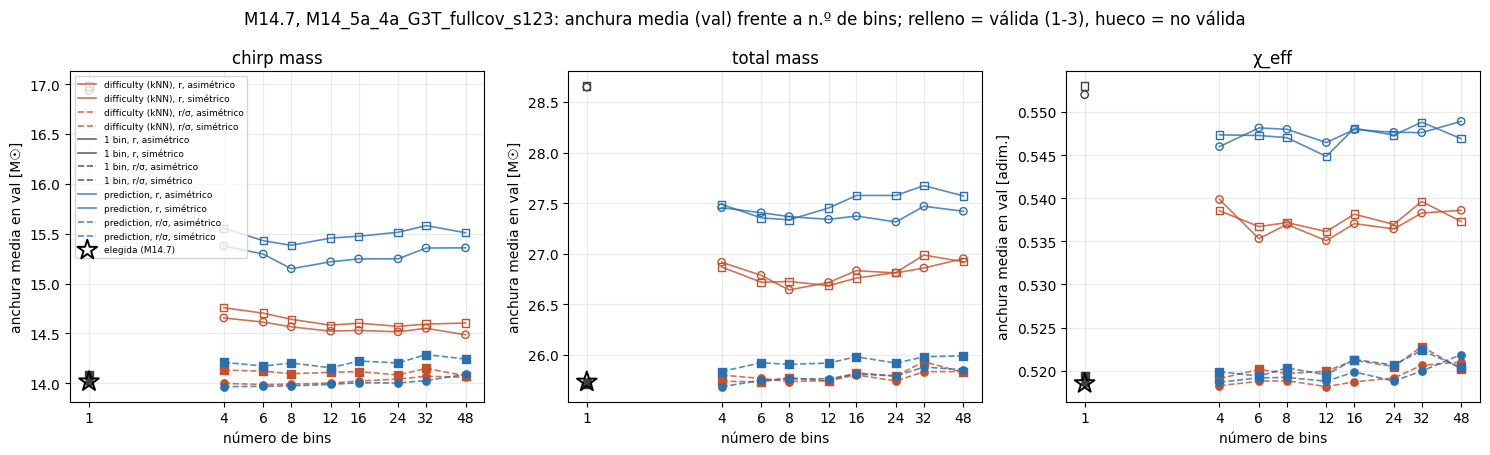

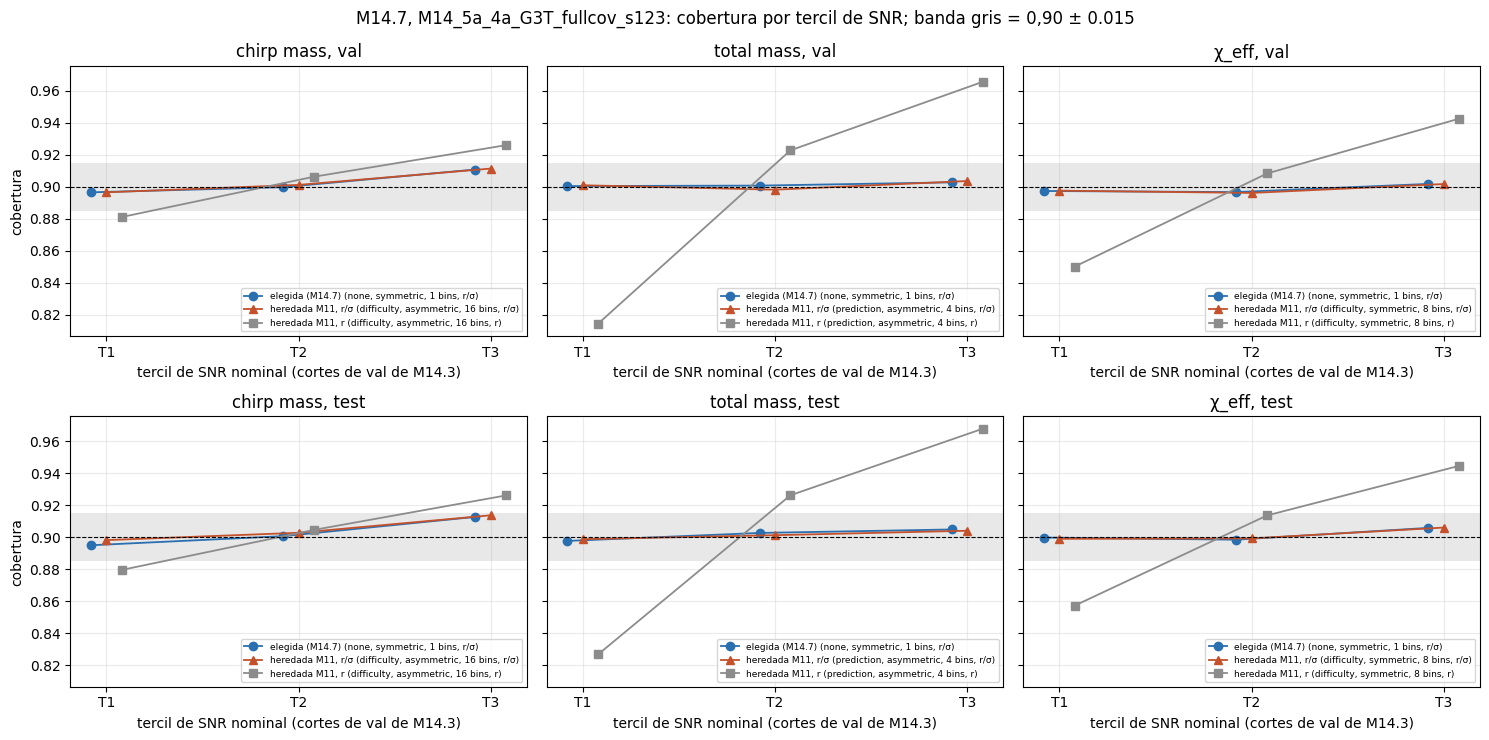

In [9]:
FIG_DIR.mkdir(parents=True, exist_ok=False)
FIGURES = []
def save_fig(fig, name):
    for ext in ("png", "pdf"):
        p = FIG_DIR / f"{name}.{ext}"
        require(not p.exists(), f"Refusing to overwrite {p}")
        fig.savefig(p, dpi=200, bbox_inches="tight")
        FIGURES.append(str(p))
    plt.show()

LNAME, UNITS = CONFIG["labels"], CONFIG["units"]

# (a) Mean width (val) against the number of bins, by taxonomy, score and interval mode; valid = filled marker.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, l in zip(axes, LABELS):
    g = GRID_VAL[GRID_VAL.label == l]
    for (tax, sc, im), t in g.groupby(["taxonomy_mode", "score", "interval_mode"]):
        t = t.sort_values("n_bins")
        st_t, st_s, st_i = CONFIG["taxonomy"][tax], CONFIG["score"][sc], CONFIG["interval"][im]
        ax.plot(t.n_bins, t.mean_width_phys, color=st_t["color"], ls=st_s["ls"], lw=1.2, alpha=0.8,
                label=f"{st_t['name']}, {st_s['name']}, {st_i['name']}")
        ax.scatter(t.n_bins[t.valid], t.mean_width_phys[t.valid], color=st_t["color"], marker=st_i["marker"], s=28, zorder=3)
        ax.scatter(t.n_bins[~t.valid], t.mean_width_phys[~t.valid], facecolors="none", edgecolors=st_t["color"],
                   marker=st_i["marker"], s=28, zorder=3)
    if SELECTED[l] is not None:
        ax.scatter([SELECTED[l][3]], [VAL_ROW[SELECTED[l]]["mean_width_phys"]], marker="*", s=220, facecolors="none", edgecolors="k",
                   linewidths=1.4, zorder=4, label=CONFIG["selected"]["name"])
    ax.set_xscale("log", base=2)
    ax.set_xticks([1] + N_BINS_GRID)
    ax.set_xticklabels([str(x) for x in [1] + N_BINS_GRID])
    ax.set_xlabel("número de bins")
    ax.set_ylabel(f"anchura media en val [{UNITS[l]}]")
    ax.set_title(LNAME[l])
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=6.5, ncol=1, loc="best")
fig.suptitle(f"M14.7, {MODEL_TAG}: anchura media (val) frente a n.º de bins; relleno = válida (1-3), hueco = no válida")
fig.tight_layout()
save_fig(fig, CONFIG["fig_names"]["width"])

# (b) Coverage per SNR tercile: selected against the inherited M11 geometry with r and r/sigma (val and test).
snr_groups = [f"SNR-T{t + 1}" for t in range(N_TERCILES)]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for row_i, split in enumerate(("val", "test")):
    for ax, l in zip(axes[row_i], LABELS):
        series = [("selected", SELECTED[l]), ("inherited_rs", INHERITED[l]["r/sigma"]), ("inherited_r", INHERITED[l]["r"])]
        for i, (role, key) in enumerate(series):
            if key is None:
                continue
            if split == "val":
                rec = VAL_ROW[key]
            else:
                test_role = {"selected": "selected", "inherited_rs": "fallback_m11_rsigma", "inherited_r": "inherited_m11_r"}[role]
                rec = test_rows[(test_role, l)]
            st = CONFIG[role]
            x = np.arange(N_TERCILES) + (i - 1) * 0.08
            ax.plot(x, [rec[f"cov_{g}"] for g in snr_groups], color=st["color"], marker=st["marker"], lw=1.3,
                    label=f"{st['name']} ({key[1]}, {key[2]}, {key[3]} bins, {CONFIG['score'][key[5]]['name']})")
        ax.axhspan(LEVEL - COND_MAX_GAP, LEVEL + COND_MAX_GAP, color=CONFIG["band_color"], alpha=0.6, lw=0)
        ax.axhline(LEVEL, color="k", ls="--", lw=0.8)
        ax.set_xticks(range(N_TERCILES))
        ax.set_xticklabels([f"T{t + 1}" for t in range(N_TERCILES)])
        ax.set_xlabel("tercil de SNR nominal (cortes de val de M14.3)")
        ax.set_title(f"{LNAME[l]}, {split}")
        ax.legend(fontsize=6.5, loc="lower right")
        ax.grid(alpha=0.25)
    axes[row_i][0].set_ylabel("cobertura")
fig.suptitle(f"M14.7, {MODEL_TAG}: cobertura por tercil de SNR; banda gris = 0,90 ± {COND_MAX_GAP}")
fig.tight_layout()
save_fig(fig, CONFIG["fig_names"]["snr"])

## 10. Resumen JSON (modo `'x'`)

In [10]:
summary = dict(
    experiment="M14.7", model=MODEL_TAG, run_stamp=RUN_STAMP, preregistration="docs/experiments/M14_7_mondrian_reselection.md",
    splits=dict(fit="cal", selection="val", confirmation="test", n=dict(cal=n_cal, val=n_val, test=len(T["idx"]))),
    search_space=dict(n_bins_grid=N_BINS_GRID, taxonomy_modes=TAXONOMY_MODES, interval_modes=INTERVAL_MODES,
                      n_neighbors_grid=N_NEIGHBORS_GRID, one_bin=ONE_BIN, scores=SCORES,
                      n_per_label=SPACE.groupby("label").size().to_dict(), n_total=len(SPACE)),
    hyperparameters=HP,
    criteria=dict(marginal_band_level=MARGINAL_BAND_LEVEL, bin_band_level=BIN_BAND_LEVEL, mc_replicas=MC_REPLICAS,
                  cond_max_gap=COND_MAX_GAP, tau_tercile_cuts_cal=TAU_CUTS_CAL, snr_tercile_cuts_val_m14_3=SNR_CUTS,
                  width_tie_fraction=WIDTH_TIE_FRACTION, seed_val=SEED_VAL, seed_test=SEED_TEST),
    inherited_m11=dict(policy=INHERITED_POLICY, geometry={l: dict(zip(KEY_COLS[1:5], g)) for l, g in INHERITED_GEO.items()}),
    grid_val=records(GRID_VAL),
    valid_val={l: records(t) for l, t in VALID_TABLES.items()},
    selected={l: key_dict(SELECTED[l]) for l in LABELS},
    bins_val_selected={l: records(BIN_VAL[SELECTED[l]]) for l in LABELS if SELECTED[l] is not None},
    test=records(GRID_TEST),
    bins_test={f"{role}/{l}": records(t) for (role, l), t in BIN_TEST.items()},
    to_use=TO_USE,
    bundle=dict(path=str(BUNDLE_PATH), sha256=BUNDLE_SHA256), selection_json=input_entry(SELECTION_JSON),
    inputs=dict(predictions={s: input_entry(p) for s, p in PRED_PATHS.items()}, split=input_entry(SPLIT_PATH),
                label_stats=input_entry(LABEL_STATS_PATH), g3_h5=str(G3_H5), m14_3_summary=input_entry(M14_3_SUMMARY),
                m11_selection=input_entry(M11_SELECTION), m11_bundle_manifest=input_entry(M11_BUNDLE_MANIFEST),
                m11_grid_provenance=input_entry(M11_GRID_PROVENANCE), npz_provenance=NPZ_PROVENANCE),
    reused_sources=reused_sources, cov_gates=records(COV_GATE) + [COV_GATE_TEST], n_checks=len(CHECKS),
    figures=FIGURES, created_utc=datetime.now(timezone.utc).isoformat(),
)
with SUMMARY_JSON.open("x") as f:
    json.dump(to_json(summary), f, indent=2)
print("Summary:", SUMMARY_JSON)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_7/M14_5a_4a_G3T_fullcov_s123/run_20261112T161005Z/M14_7_summary_20261112T161005Z.json


## Lectura (12-11-2026)

**Configuración elegida (pre-registrada, confirmada en test): 1 bin, simétrica, score r/σ, en las tres etiquetas.**

### Verificado (M14.5a; ajuste en cal, selección en val, test una vez)
- **Espacio de búsqueda:** 68 configuraciones por etiqueta (rejilla de M11: taxonomías prediction/difficulty, 4–48 bins, simétrica/asimétrica, kNN k = 5; más 1 bin; score r o r/σ).
- **Validez en val:** las 34 configuraciones con score r fallan el criterio 3 (cobertura condicional al SNR y a τ30 predicha) en las tres etiquetas; las 34 con r/σ son válidas.
- **Eficiencia en val:** entre las válidas, la anchura media varía muy poco. Mejor frente a 1 bin: chirp 13,966 (prediction, 4 bins) frente a 14,017 (+0,37 %); total 25,685 frente a 25,733 (+0,19 %); χ_eff 0,5181 (difficulty, 12 bins) frente a 0,5185 (+0,07 %). Desempate pre-registrado (dentro del 1 %, menos bins) → 1 bin.
- **Test:**
  - cobertura 0,9030 / 0,9019 / 0,9015;
  - máx. desviación condicional 0,013 / 0,009 / 0,007 (≤ 0,015);
  - anchura media 13,99 M☉ / 25,65 M☉ / 0,517 → válidas.
  - La heredada de M11 con r no es válida en test (desviación condicional 0,04–0,07; anchura 14,61 / 27,58 / 0,537).

### Interpretación
- Con un σ(x) bien calibrado, los scores normalizados son casi homogéneos y la partición de Mondrian no aporta eficiencia. La especialización del error pasa a ser continua, evento a evento (conformal normalizado).
- **Coste:** la garantía formal es marginal; la validez condicional (SNR, τ30 predicha) es empírica, comprobada en val y en test. Una configuración Mondrian con pocos bins y r/σ sería igual de eficiente y tendría garantía formal por bin. Las garantías formales en grupos solapados quedan para la fase "Mondrian final" (Gibbs et al.).

### No se puede concluir
- La optimalidad fuera del espacio de búsqueda.
- La variación entre semillas.
- El comportamiento en datos reales.